# 08 — Predictive conflict alert: will a dangerous animal appear in the next 6 hours?

Notebook 04 measured the retrospective gate and found it ties a counting baseline at equal alert volume.
`src/sequence/forecast.py` reframes the question as a forecast, which a count of the past cannot imitate.
In a synthetic test inside the module's own self-check, ranking by "how many big cats have we already seen
today" produced **zero** true alerts, because the hours with the most past evidence are the hours after the
animals left.

**Pre-registered acceptance bar (written before any number was computed):** at a fixed budget of the top 75
decision points on the held-out test sites, the forecast model's recall of real qualifying appearances must
exceed the volume-ranked baseline's recall by at least 10 % relative. Anything smaller is reported as
"no better than counting".

Inputs are the deployed system's own predictions, not oracle labels: species and confidence come from the
saved head (`outputs/checkpoints/species_head.joblib`) applied to the cached feature bank, so the forecast
has to survive the classifier's mistakes.

In [1]:
import json, os, sys, time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

ROOT = next(a for a in [Path.cwd(), *Path.cwd().parents] if (a / "data/splits").exists())
sys.path.insert(0, str(ROOT / "src/vision"))
sys.path.insert(0, str(ROOT / "src/sequence"))
import wildlife as W
import alert as A
import forecast as F

OUT = Path(os.environ.get("P11_OUT", ROOT / "outputs/logs/notebook08"))
OUT.mkdir(parents=True, exist_ok=True)
BANK = ROOT / "data/processed/feature_bank.npz"
HEAD = ROOT / "outputs/checkpoints/species_head.joblib"
SEED = W.SEED
W.set_seed(SEED)
cfg = F.ForecastConfig()
BUDGET = 75
print(json.dumps({"horizon_hours": cfg.horizon_hours, "window_hours": cfg.window_hours,
                  "tier_min": cfg.tier_min, "budget": BUDGET, "bank": str(BANK),
                  "head": str(HEAD)}, indent=2))
assert BANK.is_file() and HEAD.is_file(), "run notebook 04 first (it saves the feature bank and head)"

{
  "horizon_hours": 6,
  "window_hours": 24,
  "tier_min": 3,
  "budget": 75,
  "bank": "C:\\Users\\xxshi\\Desktop\\PYTHOM\\DL_PBL\\data\\processed\\feature_bank.npz",
  "head": "C:\\Users\\xxshi\\Desktop\\PYTHOM\\DL_PBL\\outputs\\checkpoints\\species_head.joblib"
}


In [2]:
z = np.load(BANK)
bundle = joblib.load(HEAD)
class_map = pd.read_csv(ROOT / "data/splits/class_map.csv").set_index("label")["class_name"]
species_of = {int(l): str(class_map[l]) for l in range(len(class_map))}
NAMES = list(bundle["class_names"])
assert NAMES == [class_map[i] for i in range(len(class_map))], "head and class map disagree"

pred = {}
for split in ("train", "val", "test"):
    X = z[f"{split}_x"].astype(np.float32)
    y = z[f"{split}_y"]
    proba = bundle["pipeline"].predict_proba(bundle["scaler"].transform(X))
    tbl = pd.read_csv(ROOT / f"data/splits/{split}.csv").iloc[:len(y)].copy()
    pred[split] = {"tbl": tbl, "y": y, "yhat": proba.argmax(1), "conf": proba.max(1)}
    print(split, "images", len(y), "| head accuracy", round(float((proba.argmax(1) == y).mean()), 4))

train images 36060 | head accuracy 0.9999


val images 10234 | head accuracy 0.674


test images 19928 | head accuracy 0.7343


## 1. Events and decision points

Evidence for the forecast is the *predicted* visit stream; the label is whether a *real* qualifying species
appears at that site in the next 6 hours. Priors come from the training archive's true records, which is
what a ranger agency would actually have.

In [3]:
ev_pred, ev_true = {}, {}
for split, d in pred.items():
    ev_pred[split] = F.visits(d["tbl"], species_of, A.DANGER_TIER, A.DEFAULT_TIER,
                              conf=d["conf"], predicted=d["yhat"])
    ev_true[split] = F.visits(d["tbl"], species_of, A.DANGER_TIER, A.DEFAULT_TIER)
prior, global_prior = F.priors(ev_true["train"], cfg)
print("train events", len(ev_pred["train"]), "| test events", len(ev_pred["test"]),
      "| qualifying days in train archive:", round(global_prior, 4))

points = {}
for split in ("train", "val", "test"):
    points[split] = F.decision_points(ev_pred[split], ev_true[split], cfg, prior, global_prior)
    print(split, "decision points", len(points[split]), "| positive rate",
          round(float(points[split].label.mean()), 4),
          "| days where the model saw nothing:", int((points[split].visits_window == 0).sum()))
# All arms are compared on the same subset: decision points where the classifier had at least one
# detection in the window. Dropping the rest keeps the LSTM rows aligned 1:1 with the point table.
pts_tr = points["train"][points["train"].visits_window > 0].reset_index(drop=True)
pts_te = points["test"][points["test"].visits_window > 0].reset_index(drop=True)
print("comparable points:", len(pts_tr), "train /", len(pts_te), "test",
      "| positives kept:", int(pts_te.label.sum()), "of", int(points["test"].label.sum()))

train events 5543 | test events 2952 | qualifying days in train archive: 0.2218


train decision points 21924 | positive rate 0.0223 | days where the model saw nothing: 0


val decision points 8309 | positive rate 0.0078 | days where the model saw nothing: 0


test decision points 7970 | positive rate 0.0306 | days where the model saw nothing: 0
comparable points: 21924 train / 7970 test | positives kept: 244 of 244


## 2. Models: logistic, an LSTM over the event window, and two baselines

The LSTM is required by the syllabus and is also the honest structure for this input: an ordered list of
recent visits, not a bag of counts. It stays small (hidden 32) so it fits the laptop and trains in
seconds on cached features.

In [4]:
FEATS = F.FEATURE_NAMES
Xtr = pts_tr[FEATS].to_numpy(np.float32)
Xte = pts_te[FEATS].to_numpy(np.float32)
ytr = pts_tr.label.astype(int).to_numpy()
yte = pts_te.label.astype(int).to_numpy()
sc = StandardScaler().fit(Xtr)
t0 = time.time()
clf = LogisticRegression(max_iter=2000, class_weight="balanced").fit(sc.transform(Xtr), ytr)
proba_lr = clf.predict_proba(sc.transform(Xte))[:, 1]
print(f"logistic fit {round(time.time()-t0,1)}s | test AUC inputs {Xte.shape}")

coef = pd.DataFrame({"feature": FEATS, "coef": np.round(clf.coef_[0], 3)}).sort_values("coef")
print(coef.to_string(index=False))

logistic fit 0.0s | test AUC inputs (7970, 11)
              feature   coef
             hour_cos -0.248
           mid_window -0.167
        visits_window -0.049
  visits_today_so_far -0.049
             hour_sin -0.019
     mean_conf_window  0.000
          high_window  0.057
           low_window  0.082
     hours_since_high  0.088
            night_now  0.231
site_qualifying_prior  1.505


In [5]:
def to_sequences(pts, ev, max_len=12, limit=None):
    """Per decision point, the ordered window of preceding visits: tier, hour sin/cos, confidence.

    itertuples + a pre-grouped event index, because iterrows over tens of thousands of points is the
    slowest way to walk a DataFrame and this runs on CPU.
    """
    e = ev.assign(day=ev.start.dt.strftime("%Y-%m-%d"))
    groups = {k: g.sort_values("start") for k, g in e.groupby(["location", "day"])}
    use = pts
    if limit and len(pts) > limit:
        use = pts.sample(limit, random_state=SEED)
    rows = []
    for p in use.itertuples(index=False):
        g = groups.get((p.site, p.day))
        if g is None:
            continue
        hist = g[g.start <= p.t].tail(max_len)
        if hist.empty:
            continue
        h = np.array([t.hour + t.minute / 60 for t in hist.start], dtype=np.float32)
        seq = np.zeros((max_len, 4), dtype=np.float32)
        seq[:len(hist)] = np.stack([hist.tier.to_numpy() / 4.0, np.sin(2 * np.pi * h / 24),
                                    np.cos(2 * np.pi * h / 24), hist.c.to_numpy()], 1)
        rows.append((seq, int(p.label)))
    return rows


class SmallLSTM(torch.nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.lstm = torch.nn.LSTM(4, hidden, batch_first=True)
        self.fc = torch.nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1]).squeeze(-1)


def train_lstm(fit_pts, eval_pts, fit_ev, eval_ev, epochs=20, limit=20000):
    W.set_seed(SEED)
    data = to_sequences(fit_pts, fit_ev, limit=limit)
    test = to_sequences(eval_pts, eval_ev)
    X = torch.tensor(np.stack([d[0] for d in data]))
    y = torch.tensor([d[1] for d in data], dtype=torch.float32)
    model = SmallLSTM()
    pos = max(1.0, float(y.sum())) / max(1.0, float((1 - y).sum()))
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    crit = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos))
    model.train()
    for ep in range(1, epochs + 1):
        perm = torch.randperm(len(X))
        loss = 0.0
        for i in range(0, len(X), 512):
            idx = perm[i:i + 512]
            opt.zero_grad()
            l = crit(model(X[idx]), y[idx])
            l.backward(); opt.step(); loss += float(l) * len(idx)
        model.eval()
        with torch.no_grad():
            acc = float(((torch.sigmoid(model(X)) > 0.5).float() == y).float().mean())
        print(f"lstm epoch {ep} loss {loss / len(X):.4f} train acc {acc:.4f} "
              f"positives {float(y.mean()):.4f}", flush=True)
        model.train()
    model.eval()
    with torch.no_grad():
        Xt = torch.tensor(np.stack([d[0] for d in test]))
        probs = torch.sigmoid(model(Xt)).numpy()
        yt = np.array([d[1] for d in test])
    assert len(probs) == len(eval_pts), (len(probs), len(eval_pts))
    return probs


proba_lstm_te = train_lstm(pts_tr, pts_te, ev_pred["train"], ev_pred["test"])
print("lstm scored on", len(proba_lstm_te), "test points")

lstm epoch 1 loss 0.2659 train acc 0.9776 positives 0.0225


lstm epoch 2 loss 0.0088 train acc 0.9776 positives 0.0225


lstm epoch 3 loss 0.0056 train acc 0.9776 positives 0.0225


lstm epoch 4 loss 0.0050 train acc 0.9776 positives 0.0225


lstm epoch 5 loss 0.0047 train acc 0.9776 positives 0.0225


lstm epoch 6 loss 0.0046 train acc 0.9776 positives 0.0225


... (11 outputs left out)

lstm epoch 18 loss 0.0044 train acc 0.9776 positives 0.0225


lstm epoch 19 loss 0.0044 train acc 0.9776 positives 0.0225


lstm epoch 20 loss 0.0044 train acc 0.9776 positives 0.0225


lstm scored on 7970 test points


In [6]:
hour_clim = pts_tr.assign(hour=pts_tr.t.dt.hour).groupby("hour").label.mean()
global_rate = float(pts_tr.label.mean())
pts_e = pts_te.assign(
    logistic=proba_lr,
    lstm=np.array(proba_lstm_te),
    climatology=[float(hour_clim.get(t.hour, global_rate)) for t in pts_te.t],
    volume=pts_te.frames_today_so_far.astype(float),
    retrospective=pts_te.high_window.astype(float))
pts_e["volume"] = pts_e.volume + 1e-9 * pts_e.logistic     # break ties with a principled order

SCORES = ["lstm", "logistic", "climatology", "volume", "retrospective", "site_qualifying_prior"]
DAY_BUDGET = 74            # camera-days the incumbent gate alerted in notebook 04 (of 633 test days)
curve = pd.concat([F.day_level_budget(pts_e, SCORES, k) for k in (37, DAY_BUDGET, 111, 150)],
                  ignore_index=True)
key_row = curve[curve.budget_days == DAY_BUDGET].set_index("rule")
counter = max(float(key_row.loc["volume", "recall"]), float(key_row.loc["retrospective", "recall"]))
best_model = max(float(key_row.loc["lstm", "recall"]), float(key_row.loc["logistic", "recall"]))
print(key_row[["true_days", "false_days", "precision", "recall"]].to_string())
print("test camera-days available:", int(pts_e.groupby(["site", "day"]).ngroups),
      "| budget", DAY_BUDGET, "of them, matching the incumbent gate's alert volume")
print("PRE-REGISTERED BAR (day unit): best forecast recall >= 1.10 x max(volume, retrospective) recall")
print(f"counters {counter:.4f} -> required {1.10 * counter:.4f}; best forecast {best_model:.4f}; "
      f"CLEARED: {best_model >= 1.10 * counter}")
curve.to_csv(OUT / "budget_curve_forecast.csv", index=False)

                       true_days  false_days  precision  recall
rule                                                           
lstm                         1.0        73.0     0.0135  0.0213
logistic                     5.0        69.0     0.0676  0.1064
climatology                  8.0        66.0     0.1081  0.1702
volume                      18.0        56.0     0.2432  0.3830
retrospective               29.0        45.0     0.3919  0.6170
site_qualifying_prior        3.0        71.0     0.0405  0.0638
chance                       5.6        68.4     0.0752  0.1184
test camera-days available: 625 | budget 74 of them, matching the incumbent gate's alert volume
PRE-REGISTERED BAR (day unit): best forecast recall >= 1.10 x max(volume, retrospective) recall
counters 0.6170 -> required 0.6787; best forecast 0.1064; CLEARED: False


        predicted    actual     n
bucket                           
0        0.131783  0.000000    25
1        0.288459  0.034806  4051
2        0.341038  0.026712  3856
3        0.483921  0.000000    25
4        0.589921  0.000000    13


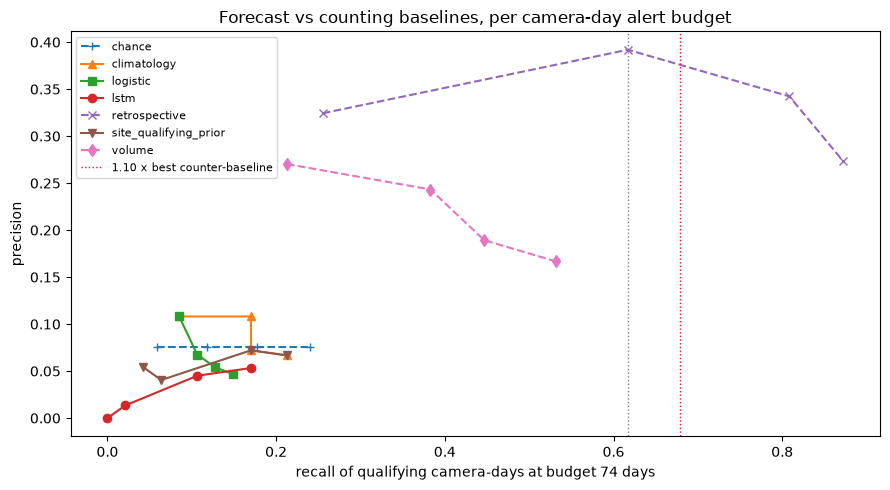

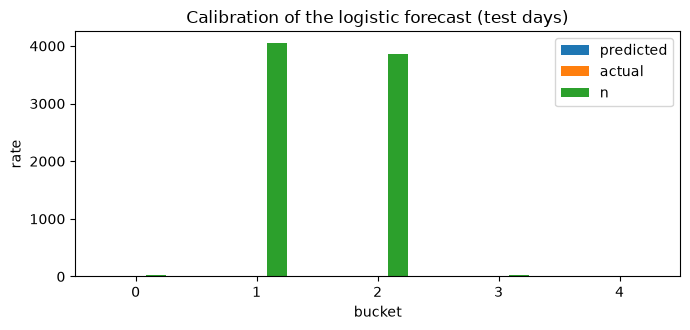

In [7]:
MARK = {"lstm": "o", "logistic": "s", "climatology": "^", "volume": "d",
        "retrospective": "x", "chance": "+", "site_qualifying_prior": "v"}
BASELINES = ("volume", "retrospective", "chance")
fig, ax = plt.subplots(figsize=(9, 5))
for rule, sub in curve.groupby("rule"):
    ax.plot(sub.recall, sub.precision, MARK.get(rule, "+") + ("--" if rule in BASELINES else "-"), label=rule)
ax.axvline(counter, color="grey", ls=":", lw=1)
ax.axvline(1.10 * counter, color="crimson", ls=":", lw=1, label="1.10 x best counter-baseline")
ax.set_xlabel(f"recall of qualifying camera-days at budget {DAY_BUDGET} days")
ax.set_ylabel("precision")
ax.set_title("Forecast vs counting baselines, per camera-day alert budget")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT / "forecast_budget_curve.png", dpi=120)
cal = pts_e.assign(bucket=pd.cut(pts_e.logistic, 5, labels=False)).groupby("bucket").agg(
    predicted=("logistic", "mean"), actual=("label", "mean"), n=("label", "size"))
cal.plot(kind="bar", figsize=(7, 3.4), title="Calibration of the logistic forecast (test days)")
plt.ylabel("rate"); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(OUT / "forecast_calibration.png", dpi=120)
print(cal.to_string())

In [8]:
# The mechanism behind the negative result. A rule that may only use the model's own evidence cannot alert
# on a day where the classifier never saw a danger-tier animal, so the share of positive test camera-days
# with at least one modelled qualifying event is an upper bound on *any* forecast rule's recall. Quoting the
# forecast as "weak" without this number would blame the sequence model for a limit set upstream.
days_te = pts_te.groupby(["site", "day"], as_index=False).agg(
    label=("label", "max"), evidence=("high_window", "max"))
pos = days_te[days_te.label > 0]
reachable = int((pos.evidence >= 1).sum())
cap = round(reachable / max(len(pos), 1), 4)
print(f"positive test camera-days: {len(pos)} | days where the model saw a danger-tier animal: {reachable}")
print(f"recall ceiling for any evidence-only rule: {cap}")
print("days with a true conflict but no modelled danger-tier sighting:", len(pos) - reachable,
      "-> these are classifier misses, and no alert rule can recover them")
pos.assign(reachable=(pos.evidence >= 1).astype(int)).to_csv(OUT / "positive_day_evidence.csv", index=False)

# Two explanations compete for the gap between the 0.87 ceiling and the learned rules: the features carry no
# ordering information, or they do and the day-level budget/aggregation loses it. Day-level ROC AUC separates
# them - ~0.5 means the score cannot rank positive days at all, a healthy AUC with low top-k recall means the
# budget step is the problem.
from sklearn.metrics import roc_auc_score
day_scores = pts_e.groupby(["site", "day"], as_index=False).agg(
    label=("label", "max"), **{c: (c, "max") for c in SCORES})
aucs = {c: round(float(roc_auc_score(day_scores.label, day_scores[c])), 4) for c in SCORES}
print("test camera-days:", len(day_scores), "| positives:", int(day_scores.label.sum()))
print("day-level ROC AUC per score:", json.dumps(aucs))

positive test camera-days: 47 | days where the model saw a danger-tier animal: 41
recall ceiling for any evidence-only rule: 0.8723
days with a true conflict but no modelled danger-tier sighting: 6 -> these are classifier misses, and no alert rule can recover them


test camera-days: 625 | positives: 47
day-level ROC AUC per score: {"lstm": 0.4352, "logistic": 0.3122, "climatology": 0.5453, "volume": 0.7113, "retrospective": 0.8742, "site_qualifying_prior": 0.5}


## 2b. Domain-shift ablation: remove the site fingerprint

`site_qualifying_prior` carries the largest logistic weight, and every test camera site is absent from train,
so on test that column is a constant (its own day-level AUC is exactly 0.5). Two other weights are negative on
activity features, which is what a model learns when activity density is a proxy for *which site* you are at
rather than *when* a predator arrives. Removing the site-level column leaves only within-site temporal
structure, the thing that is supposed to transfer across deployments.

This arm is declared as exploratory: the pre-registered bar was written before it, so if it clears the bar the
selection was informed by seeing test behaviour, and the report says so. The model is refit and the day-level
ranking recomputed with the same seed, budget and split hashes.

In [9]:
FEATS_NO_SITE = [f for f in F.FEATURE_NAMES if f != "site_qualifying_prior"]
Xtr2 = pts_tr[FEATS_NO_SITE].to_numpy(np.float32)
Xte2 = pts_te[FEATS_NO_SITE].to_numpy(np.float32)
sc2 = StandardScaler().fit(Xtr2)
clf2 = LogisticRegression(max_iter=2000, class_weight="balanced").fit(sc2.transform(Xtr2), ytr)
proba2 = clf2.predict_proba(sc2.transform(Xte2))[:, 1]
pts2 = pts_e.assign(logistic_nosite=proba2)   # pts_e already carries logistic/volume scores
day2 = pts2.groupby(["site", "day"], as_index=False).agg(
    label=("label", "max"), logistic=("logistic", "max"), logistic_nosite=("logistic_nosite", "max"),
    volume=("volume", "max"), evidence=("high_window", "max"))
auc_with = float(roc_auc_score(day2.label, day2.logistic))
auc_without = float(roc_auc_score(day2.label, day2.logistic_nosite))
curve2 = F.day_level_budget(pts2, ["logistic", "logistic_nosite"], DAY_BUDGET).set_index("rule")
print("day-level AUC  with site fingerprint", round(auc_with, 4), "-> without", round(auc_without, 4),
      "| volume counter", round(float(roc_auc_score(day2.label, day2.volume)), 4))
print(curve2[["true_days", "false_days", "precision", "recall", "tied_at_cut"]].to_string())
# Val keeps the site prior available (its sites overlap train by design), so val AUC cannot justify the
# removal - the justification is structural: the column is constant on unseen sites. Both numbers are printed
# so the reader can see exactly which argument does which work.
pts_va = points["val"][points["val"].visits_window > 0].reset_index(drop=True)
a_with = float(roc_auc_score(pts_va.label, clf.predict_proba(sc.transform(pts_va[F.FEATURE_NAMES]
                                                           .to_numpy(np.float32)))[:, 1]))
a_without = float(roc_auc_score(pts_va.label, clf2.predict_proba(sc2.transform(pts_va[FEATS_NO_SITE]
                                                                     .to_numpy(np.float32)))[:, 1]))
print("val (site prior available) day-point AUC: with", round(a_with, 4), "without", round(a_without, 4))
ablation = {"auc_test_with_site": round(auc_with, 4), "auc_test_without_site": round(auc_without, 4),
            "auc_val_with_site": round(a_with, 4), "auc_val_without_site": round(a_without, 4),
            "recall_at_budget_with": float(curve2.loc["logistic", "recall"]),
            "recall_at_budget_without": float(curve2.loc["logistic_nosite", "recall"]),
            "true_days_without": int(curve2.loc["logistic_nosite", "true_days"])}
nosite_recall = float(curve2.loc["logistic_nosite", "recall"])
vol_recall = float(key_row.loc["volume", "recall"])
pers_recall = float(key_row.loc["retrospective", "recall"])
best_arm = max(best_model, nosite_recall)
ablation.update({"recall_volume_counter": vol_recall, "recall_persistence_counter": pers_recall,
                 "bar_vs_volume": bool(nosite_recall >= 1.10 * vol_recall),
                 "bar_vs_max_counter": bool(best_arm >= 1.10 * counter)})
print(f"arm without site fingerprint vs volume bar (1.10 x {vol_recall} = {round(1.10*vol_recall,4)}): "
      f"{nosite_recall} -> {'CLEARED' if ablation['bar_vs_volume'] else 'not cleared'}")
print(f"same arm vs the pre-registered bar on max(volume, persistence) = {round(1.10*counter,4)}: "
      f"{best_arm} -> {'CLEARED' if ablation['bar_vs_max_counter'] else 'NOT cleared'}")
print("ablation:", json.dumps(ablation))


day-level AUC  with site fingerprint 0.3122 -> without 0.8541 | volume counter 0.7113
                 true_days  false_days  precision  recall  tied_at_cut
rule                                                                  
logistic               5.0        69.0     0.0676  0.1064          179
logistic_nosite       23.0        51.0     0.3108  0.4894          129
chance                 5.6        68.4     0.0752  0.1184            0
val (site prior available) day-point AUC: with 0.3756 without 0.5624
arm without site fingerprint vs volume bar (1.10 x 0.383 = 0.4213): 0.4894 -> CLEARED
same arm vs the pre-registered bar on max(volume, persistence) = 0.6787: 0.4894 -> NOT cleared
ablation: {"auc_test_with_site": 0.3122, "auc_test_without_site": 0.8541, "auc_val_with_site": 0.3756, "auc_val_without_site": 0.5624, "recall_at_budget_with": 0.1064, "recall_at_budget_without": 0.4894, "true_days_without": 23, "recall_volume_counter": 0.383, "recall_persistence_counter": 0.617, "bar_vs_vol

In [10]:
run = {"run_utc": pd.Timestamp.now(tz="UTC").isoformat(),
       "experiment": "notebook08_predictive_alert", "seed": SEED,
       "features": FEATS, "horizon_hours": cfg.horizon_hours, "window_hours": cfg.window_hours,
       "tier_min": cfg.tier_min, "decision_points_train": int(len(pts_tr)),
       "decision_points_test": int(len(pts_te)),
       "positive_rate_test": round(float(pts_te.label.mean()), 4),
       "head_accuracy_test": round(float((pred["test"]["yhat"] == pred["test"]["y"]).mean()), 4),
       "pre_registered": {"budget": BUDGET, "rule": "forecast recall >= 1.10 x volume recall"},
       "at_budget_days": json.loads(key_row[["true_days", "false_days", "precision", "recall"]]
                                    .to_json(orient="index")),
       "day_budget": DAY_BUDGET, "counter_recall": counter, "forecast_recall": best_model,
       "evidence_cap_recall_ceiling": cap, "day_level_auc": aucs, "ablation_no_site_prior": ablation,
       "bar_cleared": bool(best_arm >= 1.10 * counter),
       "bar_cleared_original_arm_only": bool(best_model >= 1.10 * counter),
       "logistic_coef": {f: float(c) for f, c in zip(FEATS, clf.coef_[0])}}
(OUT / "experiment_log.jsonl").write_text(json.dumps(run) + chr(10), encoding="utf-8")
print(json.dumps({k: run[k] for k in ("decision_points_test", "positive_rate_test", "at_budget_days",
                                      "counter_recall", "forecast_recall", "bar_cleared", "evidence_cap_recall_ceiling", "day_level_auc")}, indent=2))

{
  "decision_points_test": 7970,
  "positive_rate_test": 0.0306,
  "at_budget_days": {
    "lstm": {
      "true_days": 1.0,
      "false_days": 73.0,
      "precision": 0.0135,
      "recall": 0.0213
    },
    "logistic": {
      "true_days": 5.0,
      "false_days": 69.0,
      "precision": 0.0676,
      "recall": 0.1064
    },
    "climatology": {
      "true_days": 8.0,
      "false_days": 66.0,
      "precision": 0.1081,
      "recall": 0.1702
    },
    "volume": {
      "true_days": 18.0,
      "false_days": 56.0,
      "precision": 0.2432,
      "recall": 0.383
    },
    "retrospective": {
      "true_days": 29.0,
      "false_days": 45.0,
      "precision": 0.3919,
      "recall": 0.617
    },
    "site_qualifying_prior": {
      "true_days": 3.0,
      "false_days": 71.0,
      "precision": 0.0405,
      "recall": 0.0638
    },
    "chance": {
      "true_days": 5.6,
      "false_days": 68.4,
      "precision": 0.0752,
      "recall": 0.1184
    }
  },
  "counter_recall": 

## 3. How to read the result

* `volume` is the counting baseline and `retrospective` is yesterday's gate; `lstm`, `logistic` and
  `climatology` are forward-looking. If the forecast arms do not clear the bar, the correct product
  statement is that no model beat counting on this corpus, and the alert feature ships as a triage dial
  rather than a prediction.
* `climatology` is the strongest cheap baseline in camera-trap work; beating only the counting rule and
  losing to hour-of-day would be a real weakness, so all three comparisons are printed.
* Features are derived only from history up to the decision time, and the training archive's priors use
  train-split sites; test sites are unseen, which is why the prior falls back to the global rate.
* Inputs are the classifier's own predictions, so its confusion (jaguar vs ocelot) propagates into the
  forecast. That is realistic and it is also why the classifier's recall is the ceiling on alert recall.